In [13]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


### Preparing the dataset


**Use only the following columns:**

'engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg'

In [4]:
model = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']

In [5]:
df_1 = df[model]

In [6]:
df_1.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


**EDA**

Look at the fuel_efficiency_mpg variable. Does it have a long tail?

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

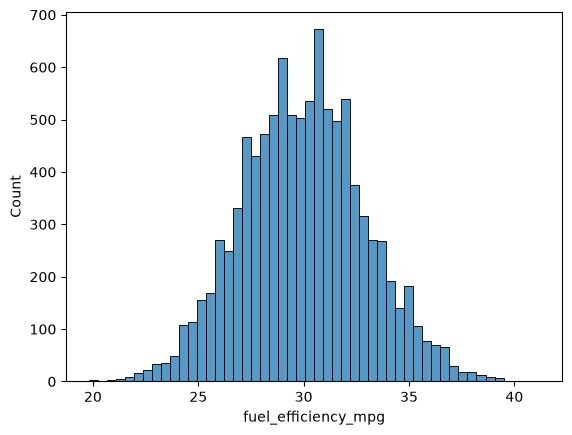

In [8]:
sns.histplot(df_1.fuel_efficiency_mpg, bins=50)

I see two long tails, so I can say it has long tail

#### Question 1

There's one column with missing values. What is it?

'engine_displacement'
'horsepower'
'vehicle_weight'
'model_year'

In [38]:
df_1.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

Horsepower is the collumn with missing values.

#### Question 2

What's the median (50% percentile) for variable 'horsepower'?

In [39]:
df_1.median()

engine_displacement    2270.0
horsepower              254.0
vehicle_weight         4280.0
model_year             2000.0
fuel_efficiency_mpg      30.0
dtype: float64

Answer: The median for horsepower is 254.0

**Prepare and split the dataset**

Shuffle the filtered dataset and create the split exactly as in the lecture:

In [40]:
import numpy as np

In [41]:
n = len(df_1)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [42]:
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

In [43]:
df_train = df_1.iloc[idx[:n_train]]
df_val = df_1.iloc[idx[n_train:n_train + n_val]]
df_test = df_1.iloc[idx[n_train + n_val:]]

In [44]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7


In [45]:
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [46]:
#ressetting the index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [47]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,1900,239.0,3790,2015,32.5
1,2000,224.0,4380,1992,29.1
2,2330,286.0,4090,2022,34.1
3,2300,NaN,4150,1997,30.6
4,2340,269.0,4400,2001,30.7


For Q5, repeat the same block with each listed seed. For Q6, use seed 9.

#### Question 3

* We need to deal with missing values for the column from Q1.
* We have two options: fill it with 0 or with the mean of this variable.
* Try both options. For each, train a linear regression model without regularization using the code from the lessons.
* For computing the mean, use the training only!
* Use the validation dataset to evaluate the models and compare the RMSE of each option.
* Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.


Which option gives better RMSE?

Options:

* With 0
* With mean <---
* Both are equally good


##### Utilities



save the columns with Y's, fuel_efficiency_mpg

In [48]:
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

remove the columns that contains the y's

In [49]:
#
y_train

array([3.51154544, 3.40452517, 3.55820113, ..., 3.35689712, 3.48431229,
       3.36729583], shape=(6000,))

In [50]:
#
df_train

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,1900,239.0,3790,2015,32.5
1,2000,224.0,4380,1992,29.1
2,2330,286.0,4090,2022,34.1
3,2300,NaN,4150,1997,30.6
4,2340,269.0,4400,2001,30.7
...,...,...,...,...,...
5995,2280,242.0,4590,2018,29.8
5996,2300,NaN,4240,1984,25.1
5997,2240,255.0,4190,1989,27.7
5998,2430,254.0,4280,2020,31.6


In [51]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [52]:
#
df_train

,engine_displacement,horsepower,vehicle_weight,model_year
0,1900,239.0,3790,2015
1,2000,224.0,4380,1992
2,2330,286.0,4090,2022
3,2300,NaN,4150,1997
4,2340,269.0,4400,2001
...,...,...,...,...
5995,2280,242.0,4590,2018
5996,2300,NaN,4240,1984
5997,2240,255.0,4190,1989
5998,2430,254.0,4280,2020


Linear regresation function:

In [53]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

Root mean square error function:

In [54]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

##### filling the gaps using 0s

In [55]:
def prepare_X(df):
    df = df.copy()
    
    #df['age'] = 2017 - df['year']
    #features = base + ['age']
    
    #df_num = df[features]
    df_num = df.fillna(0)
    X = df_num.values

    return X

In [59]:
type(df_train)

pandas.DataFrame

In [58]:
X_train = prepare_X(df_train)
type(X_train)

numpy.ndarray

* Train a linear regression model without regularization using the code from the lessons.

In [24]:
#X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)


In [25]:
#
y_pred = w0 + X_train.dot(w)
#y_pred = np.expm1(y_pred)
y_pred

array([3.56241747, 3.40471979, 3.52582873, ..., 3.40758805, 3.48954957,
       3.41959848], shape=(6000,))

In [26]:
#root square mean error
rmse(y_train, y_pred)

np.float64(0.07127079986896064)

<Axes: ylabel='Count'>

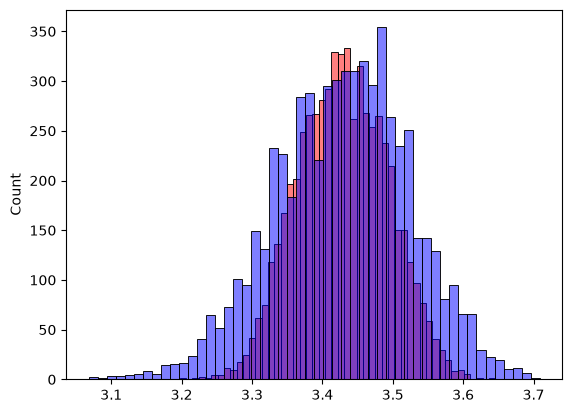

In [27]:
#
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

**Results**

Filling values nan with zeros is not that bad.

##### Filling th gaps using mean

In [60]:
df_1

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


In [61]:
#shuffle the data
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

In [62]:
df_train = df_1.iloc[idx[:n_train]]
df_val = df_1.iloc[idx[n_train:n_train + n_val]]
df_test = df_1.iloc[idx[n_train + n_val:]]

In [66]:
#mean
feature_mean = np.log1p(df_train["fuel_efficiency_mpg"].mean())
feature_mean

np.float64(3.4333343032194508)

In [67]:
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

In [68]:
def prepare_X(df):
    df = df.copy()
    
    #df['age'] = 2017 - df['year']
    #features = base + ['age']
    
    #df_num = df[features]
    df_num = df.fillna(feature_mean)
    X = df_num.values

    return X

In [72]:
X_train = prepare_X(df_train)
type(X_train)

numpy.ndarray

In [73]:
#
w0, w = train_linear_regression(X_train, y_train)
y_pred = w0 + X_train.dot(w)
y_pred

array([3.51160289, 3.40017128, 3.56288289, ..., 3.35524592, 3.48164759,
       3.3650267 ], shape=(6000,))

In [74]:
#root square mean error
rmse(y_train, y_pred)

np.float64(0.0062141596978436174)

<Axes: ylabel='Count'>

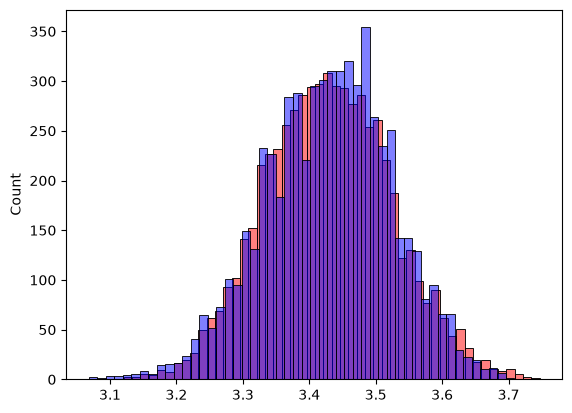

In [75]:
#
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

Answer: With mean is actually pretty good.

### Question 4

* Now let's train a regularized linear regression.
* For this question, fill the NAs with 0.
* Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
* Use RMSE to evaluate the model on the validation dataset.
* Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
* Which r gives the best RMSE?


If multiple options give the same best RMSE, select the smallest r.

Options:

* 0
* 0.01
* 0.1
* 1
* 5
* 10
* 100

In [9]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [10]:
#linear regression with regularization
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [11]:
df_1

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


In [15]:
n = len(df_1)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [16]:
#shuffle the data
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

In [20]:
#creating the datasets
df_train = df_1.iloc[idx[:n_train]]
df_val = df_1.iloc[idx[n_train:n_train + n_val]]
df_test = df_1.iloc[idx[n_train + n_val:]]

In [21]:
#ressetting the index
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [23]:
y_train = np.log1p(df_train.fuel_efficiency_mpg.values)
y_val = np.log1p(df_val.fuel_efficiency_mpg.values)
y_test = np.log1p(df_test.fuel_efficiency_mpg.values)

In [26]:
def prepare_X(df):
    df = df.copy()
    
    #df['age'] = 2017 - df['year']
    #features = base + ['age']
    
    #df_num = df[features]
    df_num = df.fillna(0)
    X = df_num.values

    return X

In [25]:
X_train = prepare_X(df_train)
type(X_train)

numpy.ndarray

In [28]:
#getting the data for the X_train
for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    
    print(r, w0, score)

0.0 2.416946748693097 0.006321050838959803
1e-05 2.416836180311358 0.006321071112349895
0.0001 2.4158415197115755 0.006321256554492476
0.001 2.4059397584468076 0.006323403389160879
0.1 1.658287950336264 0.007875467540250177
1 0.4335164979474825 0.013541677231843685
10 0.05166821856407042 0.015584159399737767


In [29]:
#getting the data for the val_train
for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(x_val, y_val, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)
    
    print(r, w0, score)

In [74]:
#root square mean error
rmse(y_train, y_pred)

np.float64(0.0062141596978436174)

<Axes: ylabel='Count'>

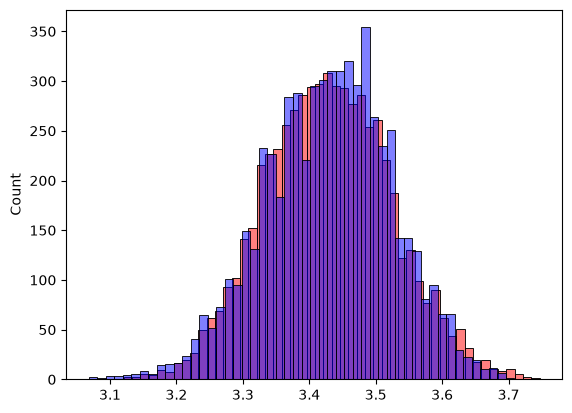

In [75]:
#
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)